In [1]:
import pandas as pd
import numpy as np
import joblib
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras import layers,models

In [2]:
data=pd.read_csv("weatherAUS.csv")

In [3]:
data.head(10)

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No
5,2008-12-06,Albury,14.6,29.7,0.2,NaN,NaN,WNW,56.0,W,...,55.0,23.0,1009.2,1005.4,NaN,NaN,20.6,28.9,No,No
6,2008-12-07,Albury,14.3,25.0,0.0,NaN,NaN,W,50.0,SW,...,49.0,19.0,1009.6,1008.2,1.0,NaN,18.1,24.6,No,No
7,2008-12-08,Albury,7.7,26.7,0.0,NaN,NaN,W,35.0,SSE,...,48.0,19.0,1013.4,1010.1,NaN,NaN,16.3,25.5,No,No
8,2008-12-09,Albury,9.7,31.9,0.0,NaN,NaN,NNW,80.0,SE,...,42.0,9.0,1008.9,1003.6,NaN,NaN,18.3,30.2,No,Yes
9,2008-12-10,Albury,13.1,30.1,1.4,NaN,NaN,W,28.0,S,...,58.0,27.0,1007.0,1005.7,NaN,NaN,20.1,28.2,Yes,No


In [4]:
data=data.dropna()

In [5]:
data=data.drop_duplicates()

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 56420 entries, 6049 to 142302
Data columns (total 23 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           56420 non-null  object 
 1   Location       56420 non-null  object 
 2   MinTemp        56420 non-null  float64
 3   MaxTemp        56420 non-null  float64
 4   Rainfall       56420 non-null  float64
 5   Evaporation    56420 non-null  float64
 6   Sunshine       56420 non-null  float64
 7   WindGustDir    56420 non-null  object 
 8   WindGustSpeed  56420 non-null  float64
 9   WindDir9am     56420 non-null  object 
 10  WindDir3pm     56420 non-null  object 
 11  WindSpeed9am   56420 non-null  float64
 12  WindSpeed3pm   56420 non-null  float64
 13  Humidity9am    56420 non-null  float64
 14  Humidity3pm    56420 non-null  float64
 15  Pressure9am    56420 non-null  float64
 16  Pressure3pm    56420 non-null  float64
 17  Cloud9am       56420 non-null  float64
 18  Cloud3p

In [7]:
LeRainToday=LabelEncoder()
LeRainTomorrow=LabelEncoder()
data["RainToday"]=LeRainToday.fit_transform(data["RainToday"])
data["RainTomorrow"]=LeRainTomorrow.fit_transform(data["RainTomorrow"])

In [8]:
x=data[["MinTemp","MaxTemp","Rainfall","WindGustSpeed","WindSpeed9am","WindSpeed3pm","Humidity9am","Humidity3pm","RainToday"]]

In [9]:
y=data["RainTomorrow"]

In [10]:
X_train,X_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [11]:
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(45136, 9)
(45136,)
(11284, 9)
(11284,)


In [12]:
model=models.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

In [13]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [14]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 32)                  │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 865 (3.38 KB)

 Trainable params: 865 (3.38 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
history=model.fit(X_train,y_train,epochs=20,validation_split=0.2,verbose=1)

Epoch 1/20
1129/1129 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8075 - loss: 0.4684 - val_accuracy: 0.8336 - val_loss: 0.4011
Epoch 2/20
1129/1129 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8254 - loss: 0.4078 - val_accuracy: 0.8325 - val_loss: 0.4036
Epoch 3/20
1129/1129 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8297 - loss: 0.4000 - val_accuracy: 0.8068 - val_loss: 0.4230
Epoch 4/20
1129/1129 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8300 - loss: 0.3971 - val_accuracy: 0.8389 - val_loss: 0.3901
Epoch 5/20
1129/1129 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8351 - loss: 0.3886 - val_accuracy: 0.8408 - val_loss: 0.3843
Epoch 6/20
1129/1129 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8363 - loss: 0.3867 - val_accuracy: 0.8272 - val_loss: 0.4033
Epoch 7/20
1129/1129 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8385 - loss: 0.3815 - val_accuracy: 0.8413 - val_loss: 0.3838
Epoch 8/20
1129/1129 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8384 - loss: 0.3813 - 

In [16]:
joblib.dump(LeRainToday,"RainToday.pkl")
joblib.dump(LeRainTomorrow,"RainTomorrow.pkl")
joblib.dump(model,"ANN_eg")
print("Saved")

Saved


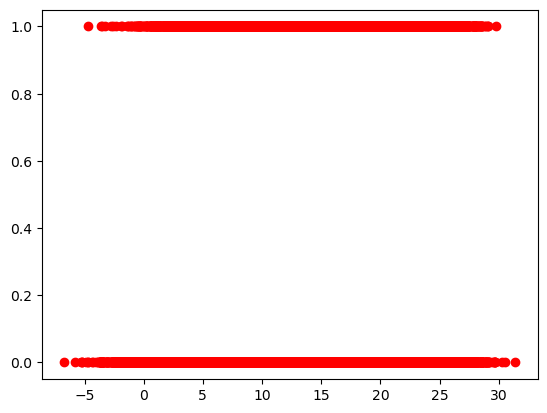

In [19]:
import matplotlib.pyplot as plt
plt.scatter(x.iloc[:,0],y,color="red")
plt.show()